# Boosting explicado fácil · Gradient Boosting
**Diseño de Soluciones de Inteligencia Artificial (CERTUS) · Sesión 5 · Tema 8**

> **Cómo usar este cuaderno:** ejecuta las celdas de arriba hacia abajo (▶ o `Shift + Enter`). Lee el texto y mira los gráficos. Lo importante es **entender qué hace cada parámetro** y verlo en el resultado.

## ¿Qué vas a aprender?
1. La idea del boosting con una analogía: el estudiante que **repasa sus errores**.
2. Un boosting **hecho a mano** paso a paso para ver cómo funciona por dentro.
3. Los **parámetros**: `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `min_samples_leaf`, `max_features`, `n_iter_no_change`...
4. La relación entre `learning_rate` y `n_estimators` (la más importante).
5. Cómo detener el entrenamiento a tiempo (**early stopping**) para no sobreajustar.
6. Qué variables importan y qué otras herramientas existen (XGBoost, LightGBM).

### Palabras que vas a ver
| Palabra | Significado fácil |
|---|---|
| **Ensamble** | Combinar varios modelos para obtener uno mejor. |
| **Modelo débil** | Un modelo muy simple, apenas mejor que adivinar (aquí: un árbol pequeño). |
| **Residuo / error** | Lo que le falta al modelo para acertar: *valor real − predicción*. |
| **Learning rate** | Qué tanto "caso" le hace el modelo a cada corrección nueva. |
| **Iteración / etapa** | Cada árbol nuevo que se agrega a la cadena. |

## 0. Preparación (ejecuta esta celda primero)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.datasets import make_moons, make_blobs, make_circles, make_classification
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEMILLA = 42
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def frontera(modelo, X, y, ax=None, titulo=""):
    # Dibuja la 'frontera de decisión' de un modelo entrenado con 2 variables:
    # el fondo rojo/azul muestra qué predice el modelo en cada punto del plano.
    ax = ax or plt.gca()
    modelo.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return modelo


def metricas(modelo, Xv, yv):
    # Calcula las métricas principales de un modelo ya entrenado.
    pred = modelo.predict(Xv)
    if hasattr(modelo, "predict_proba"):
        puntaje = modelo.predict_proba(Xv)[:, 1]
    else:
        puntaje = modelo.decision_function(Xv)
    return pd.Series({
        "exactitud": accuracy_score(yv, pred),
        "precisión": precision_score(yv, pred, zero_division=0),
        "recall": recall_score(yv, pred),
        "F1": f1_score(yv, pred),
        "AUC": roc_auc_score(yv, puntaje),
    }).round(3)

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

## 1. La idea: aprender de los errores, uno por uno
**Analogía del estudiante.** Un estudiante hace un examen de práctica y falla ciertas preguntas. En lugar de volver a estudiar todo, **repasa solo lo que falló**. Hace otro examen, vuelve a fallar menos preguntas y repasa solo esas. Después de muchas rondas, domina casi todo.

**Boosting funciona igual:**
1. Se entrena un primer modelo muy simple (un árbol pequeño). Comete errores.
2. Se entrena un segundo árbol **cuyo trabajo es corregir los errores del primero**.
3. Se entrena un tercero para corregir lo que aún falla… y así cientos de veces.
4. La predicción final es **la suma de todas las correcciones** (cada una multiplicada por el `learning_rate`).

> **Diferencia con Random Forest:** en el bosque los árboles son independientes y **votan al mismo tiempo**. En boosting los árboles son **secuenciales**: cada uno depende del anterior y se enfoca en sus errores. Por eso el boosting suele ser más preciso, pero también **más fácil de sobreajustar** y más sensible a los parámetros.

## 2. Boosting hecho a mano (para ver la magia)
Vamos a "armar" el boosting nosotros mismos con árboles diminutos para predecir una curva con ruido (una onda). Cada paso:
* calcula el **error** actual (real − predicción),
* entrena un árbol pequeño para **predecir ese error**,
* suma ese árbol a la predicción, pero **solo un poco** (multiplicado por `learning_rate`).

Paso   1: error absoluto medio = 0.461
Paso   3: error absoluto medio = 0.269
Paso  10: error absoluto medio = 0.136
Paso 100: error absoluto medio = 0.038


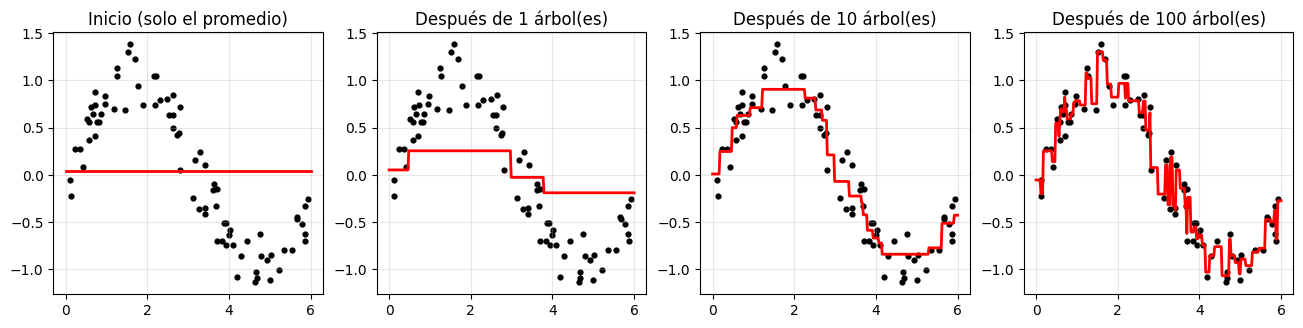

In [2]:
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0, 6, 80))
y = np.sin(x) + rng.normal(0, 0.2, 80)           # una onda con ruido
X = x.reshape(-1, 1)
xs = np.linspace(0, 6, 300).reshape(-1, 1)

learning_rate = 0.3
pred = np.full(len(y), y.mean())                  # paso 0: predice el promedio para todos
pred_xs = np.full(len(xs), y.mean())

instantaneas = {0: pred_xs.copy()}
for paso in range(1, 101):
    error = y - pred                                              # 1) ¿en qué me equivoco?
    arbol = DecisionTreeRegressor(max_depth=2).fit(X, error)      # 2) árbol pequeño que aprende ese error
    pred += learning_rate * arbol.predict(X)                      # 3) corrijo, pero solo un poco
    pred_xs += learning_rate * arbol.predict(xs)
    if paso in (1, 3, 10, 100):
        instantaneas[paso] = pred_xs.copy()
        print(f"Paso {paso:3d}: error absoluto medio = {np.abs(y - pred).mean():.3f}")

fig, ejes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (paso, p) in zip(ejes, [(0, instantaneas[0]), (1, instantaneas[1]), (10, instantaneas[10]), (100, instantaneas[100])]):
    ax.scatter(x, y, s=12, color="k"); ax.plot(xs, p, "r", lw=2)
    ax.set_title("Inicio (solo el promedio)" if paso == 0 else f"Después de {paso} árbol(es)")
plt.show()

**Cómo leerlo:** al inicio solo hay una línea plana (el promedio). Con 1 árbol ya aparece un escalón; con 10 la curva sigue la onda; con 100 se ajusta muy bien (y empieza a seguir también el ruido). **Cada árbol es débil, pero la suma es fuerte.**

En la práctica no hay que programar esto: `GradientBoostingClassifier` lo hace por ti. Pero ahora ya sabes que `n_estimators` = *cuántos pasos de corrección* y `learning_rate` = *qué tan grande es cada corrección*.

## Preparar los datos reales (caso operadora móvil)
Usamos el mismo archivo de las semanas 3 y 4: `clientes_telecom.csv`. Queremos predecir `se_fue` (1 = el cliente se fue, 0 = se quedó).

Aquí solo hacemos lo indispensable: limpieza mínima, separar una parte para **validar** y convertir las columnas a números (rellenar vacíos, escalar y pasar categorías a 0/1). Si no entiendes esta celda, no importa: **ejecútala tal cual** y sigue.

In [3]:
# Cargamos el archivo desde el repositorio del curso.
# Si no hay internet, sube clientes_telecom.csv al panel de archivos de Colab y cambia URL por "clientes_telecom.csv".
URL = "https://raw.githubusercontent.com/jeanpier22/Diseno-de-Soluciones-de-Inteligencia-Artificial/main/Practica_Semana3y4/clientes_telecom.csv"
df = pd.read_csv(URL, encoding="utf-8-sig")

# Limpieza mínima (la misma de la Sesión 5)
df = df.drop_duplicates(subset="id_cliente").copy()
df.loc[(df["edad"] < 14) | (df["edad"] > 100), "edad"] = np.nan
df.loc[df["monto_factura"] < 0, "monto_factura"] = np.nan
df["tipo_plan"] = (df["tipo_plan"].str.lower().str.replace("-", "", regex=False)
                   .replace({"prepago": "Prepago", "postpago ilimitado": "Postpago Ilimitado", "postpago básico": "Postpago Básico"}))

num = ["edad", "consumo_datos_mb", "minutos_llamadas", "recargas_mes", "monto_factura",
       "velocidad_mbps", "caidas_red_mes", "llamadas_soporte", "satisfaccion"]
cat = ["tipo_plan", "metodo_pago", "departamento"]

train = df[df["particion"] == "train"]
X_train, y_train = train[num + cat], train["se_fue"]

# Del 'train' separamos una parte para VALIDAR (examen de práctica). El 'test' no se toca en este cuaderno.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEMILLA)

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
], sparse_threshold=0)

Xp_tr = prep.fit_transform(X_tr)      # se 'aprende' solo con entrenamiento
Xp_val = prep.transform(X_val)
nombres = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
print("Clientes para entrenar:", Xp_tr.shape[0], "| para validar:", Xp_val.shape[0], "| columnas:", Xp_tr.shape[1])
print("Proporción que se va:", round(y_tr.mean(), 3))

Clientes para entrenar: 900 | para validar: 300 | columnas: 31
Proporción que se va: 0.288


### Primer modelo con parámetros por defecto

In [4]:
gb = GradientBoostingClassifier(random_state=SEMILLA)
gb.fit(Xp_tr, y_tr)
metricas(gb, Xp_val, y_val)

exactitud    0.757
precisión    0.618
recall       0.395
F1           0.482
AUC          0.805
dtype: float64

## 3. Los parámetros de `GradientBoostingClassifier` (las "perillas")
| Parámetro | Qué hace en palabras simples | Por defecto | Qué pasa si lo cambias |
|---|---|---|---|
| **`n_estimators`** | **Cuántos árboles** (pasos de corrección) se agregan. | `100` | Pocos → el modelo no alcanza a aprender (*underfitting*). Muchísimos → empieza a memorizar (*overfitting*). |
| **`learning_rate`** | **Qué tan grande es cada corrección** (entre 0 y 1). | `0.1` | Alto (0,5-1): aprende rápido pero "a los golpes" y se sobreajusta. Bajo (0,01-0,05): aprende despacio y con más precisión, pero **necesita más árboles**. |
| **`max_depth`** | Profundidad de cada árbol individual. | `3` | 1-3: árboles muy simples (suele ir mejor). Mayor a 5: árboles complejos que memorizan con facilidad. |
| **`subsample`** | Fracción de clientes que usa cada árbol (al azar). | `1.0` | 0,5-0,8 agrega "variedad" y **reduce el overfitting** (se llama *stochastic gradient boosting*). |
| **`min_samples_leaf`** | Mínimo de clientes por hoja. | `1` | Subirlo (10-30) hace cada árbol más prudente. |
| **`max_features`** | Variables que mira cada árbol en cada corte. | `None` (todas) | `"sqrt"` o 0,5: menos overfitting y entrenamiento más rápido. |
| **`n_iter_no_change`** | **Parar antes** si la validación no mejora durante N rondas (*early stopping*). | `None` | Poner 10 o 20 y dejar `n_estimators` alto: el modelo se detiene solo en el momento justo. |
| **`validation_fraction`** | Qué porción de los datos se aparta internamente para vigilar el early stopping. | `0.1` | Solo se usa junto con `n_iter_no_change`. |
| **`loss`** | Qué error intenta reducir. | `"log_loss"` | Casi nunca se cambia en clasificación. |
| **`random_state`** | Semilla. | `None` | Fíjala (42) para repetir resultados. |

> **La pareja clave:** **`learning_rate` y `n_estimators` van juntos**. Un `learning_rate` menor necesita más árboles. Una receta clásica: *`learning_rate` pequeño (0,05–0,1) + `n_estimators` alto + early stopping*.

### Experimento A · ¿Cuántos árboles? (`n_estimators`) y el momento de parar
Entrenamos con 300 árboles y medimos el AUC **después de cada árbol** en entrenamiento y validación.

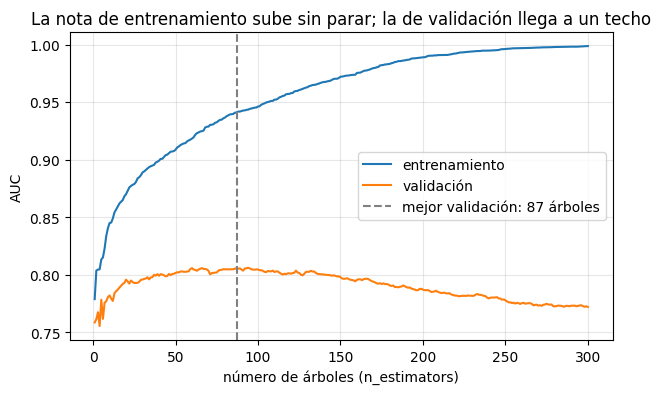

Mejor número de árboles en validación: 87  (AUC 0.806)  |  con 300 árboles: AUC 0.772


In [5]:
def curva_auc(modelo, Xa, ya, Xb, yb):
    # AUC de entrenamiento y validación después de cada árbol agregado
    modelo.fit(Xa, ya)
    a = [roc_auc_score(ya, p[:, 1]) for p in modelo.staged_predict_proba(Xa)]
    b = [roc_auc_score(yb, p[:, 1]) for p in modelo.staged_predict_proba(Xb)]
    return np.array(a), np.array(b)

a, b = curva_auc(GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=SEMILLA),
                 Xp_tr, y_tr, Xp_val, y_val)
mejor = int(np.argmax(b)) + 1

plt.plot(range(1, 301), a, label="entrenamiento")
plt.plot(range(1, 301), b, label="validación")
plt.axvline(mejor, color="gray", ls="--", label=f"mejor validación: {mejor} árboles")
plt.xlabel("número de árboles (n_estimators)"); plt.ylabel("AUC"); plt.legend()
plt.title("La nota de entrenamiento sube sin parar; la de validación llega a un techo")
plt.show()
print(f"Mejor número de árboles en validación: {mejor}  (AUC {b[mejor-1]:.3f})  |  con 300 árboles: AUC {b[-1]:.3f}")

**Cómo leerlo:** la curva de entrenamiento llega casi a 1,0 (memoriza). La de validación sube rápido al inicio y luego se **aplana o baja**. Agregar más árboles después de ese punto solo **gasta tiempo y sobreajusta**.

### Experimento B · `learning_rate`: pasos grandes vs. pasos chicos
Entrenamos tres modelos con 300 árboles y diferente `learning_rate`:

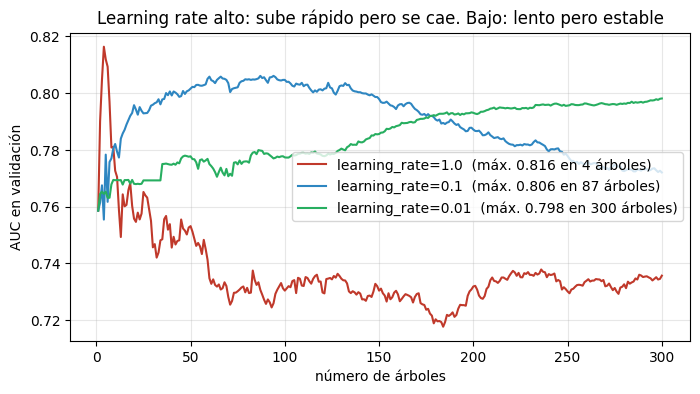

In [6]:
plt.figure(figsize=(8, 4))
for lr, color in [(1.0, "#c0392b"), (0.1, "#2e86c1"), (0.01, "#27ae60")]:
    a, b = curva_auc(GradientBoostingClassifier(n_estimators=300, learning_rate=lr, max_depth=3, random_state=SEMILLA),
                     Xp_tr, y_tr, Xp_val, y_val)
    plt.plot(range(1, 301), b, color=color, label=f"learning_rate={lr}  (máx. {b.max():.3f} en {int(np.argmax(b))+1} árboles)")
plt.xlabel("número de árboles"); plt.ylabel("AUC en validación"); plt.legend()
plt.title("Learning rate alto: sube rápido pero se cae. Bajo: lento pero estable")
plt.show()

**Cómo leerlo:**
* `learning_rate=1.0` (rojo): aprende en un instante, pero llega a un máximo bajo y luego **se cae** (se pasa de rosca).
* `learning_rate=0.1` (azul): buen equilibrio.
* `learning_rate=0.01` (verde): muy lento; con 300 árboles aún **no terminó de aprender** (necesitaría 1000+).

Como el boosting con `learning_rate` bajo es lento, por eso se acompaña de **early stopping** (más abajo).

### Experimento C · `max_depth`: ¿árboles chicos o grandes?
En boosting los árboles deben ser **débiles a propósito**. Mira lo que pasa al hacerlos más profundos:

In [7]:
filas = []
for d in [1, 2, 3, 5, 8]:
    m = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=d, random_state=SEMILLA).fit(Xp_tr, y_tr)
    filas.append({"max_depth": d,
                  "AUC entrenamiento": roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]),
                  "AUC validación": roc_auc_score(y_val, m.predict_proba(Xp_val)[:, 1])})
res = pd.DataFrame(filas).round(3)
res["brecha (overfitting)"] = (res["AUC entrenamiento"] - res["AUC validación"]).round(3)
res

,max_depth,AUC entrenamiento,AUC validación,brecha (overfitting)
0,1,0.834,0.820,0.014
1,2,0.898,0.811,0.087
2,3,0.946,0.805,0.141
3,5,1.000,0.779,0.221
4,8,1.000,0.762,0.238


**Lectura:** al aumentar `max_depth`, el AUC de entrenamiento se acerca a 1,0, pero el de validación **no mejora** (o empeora): la **brecha** crece, y esa brecha es overfitting. Para boosting suelen funcionar bien profundidades de **1 a 4**.

### Experimento D · `subsample`, `max_features` y `min_samples_leaf`: "frenos" contra el overfitting
Estas tres perillas hacen que cada árbol sea **más prudente o más variado**:

In [8]:
configs = {
    "Base (sin frenos)": dict(),
    "subsample=0.5": dict(subsample=0.5),
    "max_features='sqrt'": dict(max_features="sqrt"),
    "min_samples_leaf=15": dict(min_samples_leaf=15),
    "Los tres juntos": dict(subsample=0.7, max_features="sqrt", min_samples_leaf=15),
}
filas = {}
for nombre, p in configs.items():
    m = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, random_state=SEMILLA, **p).fit(Xp_tr, y_tr)
    filas[nombre] = {"AUC entrenamiento": roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1]),
                     "AUC validación": roc_auc_score(y_val, m.predict_proba(Xp_val)[:, 1])}
pd.DataFrame(filas).T.round(3)

,AUC entrenamiento,AUC validación
Base (sin frenos),0.972,0.798
subsample=0.5,0.983,0.792
max_features='sqrt',0.951,0.809
min_samples_leaf=15,0.964,0.791
Los tres juntos,0.933,0.805


**Lectura honesta:** los efectos son **pequeños y mixtos**. En esta corrida `max_features='sqrt'` fue lo que más ayudó en validación (~0,81), mientras que `subsample=0.5` y `min_samples_leaf=15` quedaron igual o algo por debajo. La idea es que estos "frenos" *pueden* ayudar a generalizar (el combo de los tres bajó el AUC de entrenamiento de 0,97 a 0,93: memoriza menos), pero **no son garantía**: se prueban con validación, no se asumen.

### Experimento E · Early stopping: que el modelo se detenga solo
Le damos hasta 1000 árboles, pero con `n_iter_no_change=15` el modelo reserva una parte de los datos (`validation_fraction`) y **se detiene cuando 15 rondas seguidas no mejoran**.

In [9]:
temprano = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3,
                                      n_iter_no_change=15, validation_fraction=0.15, random_state=SEMILLA)
temprano.fit(Xp_tr, y_tr)
print("Árboles pedidos: 1000   |   árboles que realmente usó:", temprano.n_estimators_)
metricas(temprano, Xp_val, y_val)

Árboles pedidos: 1000   |   árboles que realmente usó: 62


exactitud    0.773
precisión    0.667
recall       0.419
F1           0.514
AUC          0.798
dtype: float64

Pidió 1000 pero se detuvo mucho antes: **ahorró tiempo y evitó el overfitting** sin que tuviéramos que adivinar el número exacto de árboles.

### Experimento F · Ver el boosting en dibujo (datos 2D)
Con las medias lunas (`make_moons`) vemos cómo la frontera evoluciona al agregar árboles:

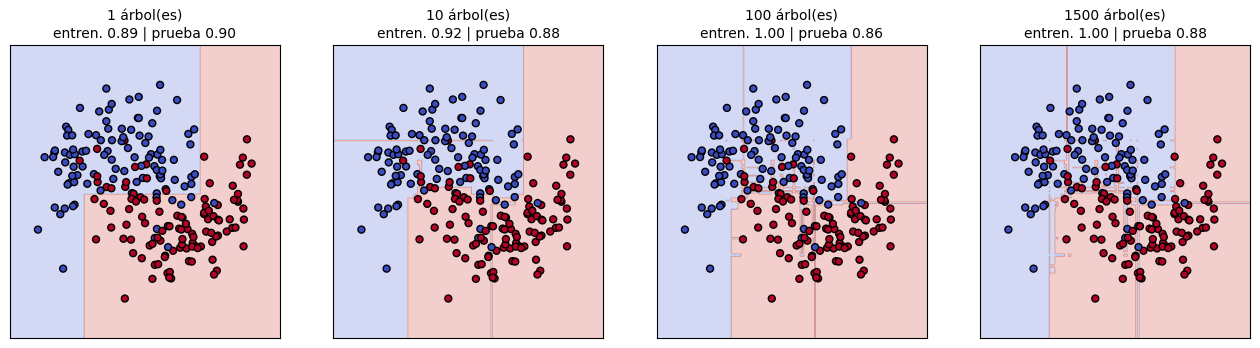

In [10]:
Xm, ym = make_moons(n_samples=300, noise=0.3, random_state=3)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=0)

fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, ne in zip(ejes, [1, 10, 100, 1500]):
    m = GradientBoostingClassifier(n_estimators=ne, learning_rate=0.3, max_depth=3, random_state=0)
    frontera(m, Xm_tr, ym_tr, ax, "")
    ax.set_title(f"{ne} árbol(es)\nentren. {m.score(Xm_tr, ym_tr):.2f} | prueba {m.score(Xm_te, ym_te):.2f}", fontsize=10)
plt.show()

* **1 árbol**: una frontera de un solo corte, muy tosca.
* **10-100 árboles**: la frontera se curva y sigue la forma de las lunas.
* **1500 árboles con learning rate alto**: se forman "islas" alrededor de puntos individuales: el modelo **memorizó el ruido**.

## 4. ¿Qué variables usa? (`feature_importances_`)

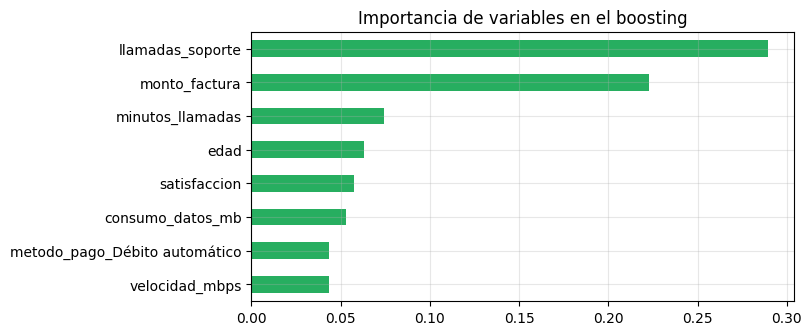

exactitud    0.780
precisión    0.692
recall       0.419
F1           0.522
AUC          0.800
dtype: float64


In [11]:
mejor_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=2, subsample=0.8, random_state=SEMILLA).fit(Xp_tr, y_tr)
imp = pd.Series(mejor_gb.feature_importances_, index=nombres).sort_values(ascending=False).head(8)
imp[::-1].plot.barh(color="#27ae60", figsize=(7, 3.5)); plt.title("Importancia de variables en el boosting"); plt.show()
print(metricas(mejor_gb, Xp_val, y_val))

Es más difícil de explicar que una logística (son 100 árboles, no una fórmula), pero la importancia de variables da una **pista global** de qué mira el modelo.

## 5. Otras herramientas de boosting (mismo concepto, más rápidas)
`GradientBoostingClassifier` es el de scikit-learn "de enseñanza". En la vida real se usan versiones más veloces y con más opciones:

| Herramienta | Comentario |
|---|---|
| `HistGradientBoostingClassifier` (scikit-learn) | Muy rápido con datos grandes; ya viene incluido; maneja valores vacíos solo. |
| **XGBoost** | Muy popular y potente (competencias de datos). Parámetros: `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`. |
| **LightGBM** | Muy rápido; ideal con muchos datos. |
| **CatBoost** | Maneja categorías sin preprocesar. |

Todos usan **las mismas perillas** que acabas de aprender (cantidad de árboles, learning rate, profundidad, submuestreo). Si dominas este cuaderno, sabes usar cualquiera.

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_depth=3, random_state=SEMILLA)
hgb.fit(Xp_tr, y_tr)
print("HistGradientBoosting (equivalente rápido):")
print(metricas(hgb, Xp_val, y_val))

HistGradientBoosting (equivalente rápido):
exactitud    0.773
precisión    0.655
recall       0.442
F1           0.528
AUC          0.796
dtype: float64


## 6. Resumen: ¿qué mover y cuándo?
| Síntoma que ves | Qué probar |
|---|---|
| Entrenamiento ≈ 1,0 y validación mucho menor (**overfitting**) | Bajar `max_depth` (1-3); bajar `learning_rate` y usar early stopping; `subsample=0.7`; subir `min_samples_leaf`. |
| Ambas notas bajas (**underfitting**) | Subir `n_estimators`; subir `max_depth` (3-4); subir un poco `learning_rate`. |
| Entrenamiento muy lento | Subir `learning_rate` y bajar `n_estimators`; usar `HistGradientBoosting`; `max_features="sqrt"`. |
| No sé cuántos árboles poner | `n_estimators=1000` + `n_iter_no_change=15` (early stopping). |

### Receta para empezar (sin pensarlo mucho)
`GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, n_iter_no_change=15, random_state=42)`

### Ventajas y límites
| ✅ Ventajas | ⚠️ Límites |
|---|---|
| Suele ser de los modelos **más precisos** en datos tabulares. | Muchas perillas; se puede sobreajustar si no se vigila. |
| No necesita escalar variables. | Más lento de entrenar (árboles en secuencia). |
| Capta relaciones complejas. | Difícil de explicar a negocio (caja casi negra). |

> **Dato de la Sesión 5:** en nuestros datos de churn el boosting **no ganó** a la logística (AUC de validación 0,805 frente a 0,843). Un modelo más complejo no siempre es mejor: **hay que medirlo siempre**.

## 7. Ejercicios
1. En el Experimento A, cambia `max_depth=3` por `max_depth=1`. ¿Cambia el número óptimo de árboles?
2. Con `learning_rate=0.5` y `n_estimators=50`, ¿mejora o empeora el AUC de validación frente al valor por defecto?
3. Prueba `subsample=0.3`. ¿Qué pasa con el AUC de entrenamiento?
4. Usa early stopping con `n_iter_no_change=5` y con `n_iter_no_change=50`. ¿Cuántos árboles usa en cada caso?
5. Para tu Evidencia 3: escribe en 3 líneas **por qué elegiste (o descartaste) el boosting** frente a la regresión logística, citando AUC y complejidad.